In [ ]:
!pip install mlxtend -q

from google.colab import drive
drive.mount('/content/drive')

import os, time
import numpy as np, pandas as pd
import pyarrow.parquet as pq
from sklearn.preprocessing import StandardScaler
from mlxtend.frequent_patterns import fpgrowth

PATH = '/content/drive/MyDrive/model_ready_trips.parquet'
OUT = '/content/drive/MyDrive/DRIFT_outputs'
os.makedirs(OUT, exist_ok=True)

schema_cols = pq.read_schema(PATH).names
need = ['trip_distance','duration_min','avg_speed_mph','fare_amount','RatecodeID',
        'PULocationID','DOLocationID','PU_borough','DO_borough']
time_col = 'time_of_day' if 'time_of_day' in schema_cols else 'pickup_hour'

df = pd.read_parquet(PATH, columns=need + [time_col])
if time_col == 'pickup_hour':
    df['time_of_day'] = pd.cut(df['pickup_hour'], bins=[-1, 5, 11, 16, 23],
                               labels=['Night', 'Morning', 'Afternoon', 'Evening'])
    df = df.drop(columns='pickup_hour')

df['log_trip_distance'] = np.log1p(df['trip_distance'])
for src, dst in [('log_trip_distance', 'z_log_trip_distance'),
                 ('duration_min', 'z_duration_min'),
                 ('avg_speed_mph', 'z_avg_speed_mph')]:
    df[dst] = StandardScaler().fit_transform(df[[src]]).ravel()

airport_ids = {1, 132, 138}
df['is_airport_trip'] = (df['PULocationID'].isin(airport_ids)
                         | df['DOLocationID'].isin(airport_ids)
                         | df['RatecodeID'].isin([2, 3]))

print(df.shape, "| airport share:", round(df['is_airport_trip'].mean(), 3))

Mounted at /content/drive
(2828026, 15) | airport share: 0.097


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## **MODULE B: FP-Growth Association Rules:**

In [ ]:
fp = df.sample(200_000, random_state=42)

basket = pd.get_dummies(
    fp[['time_of_day', 'RatecodeID', 'PU_borough', 'DO_borough']].astype(str),
    dtype=bool)
basket['is_airport_trip'] = fp['is_airport_trip'].values
basket['is_surge_fare'] = (fp['fare_amount'] > fp['fare_amount'].quantile(0.75)).values

MIN_SUP = 0.01
basket = basket.loc[:, basket.mean() >= MIN_SUP]

t = time.time()
freq = fpgrowth(basket, min_support=MIN_SUP, use_colnames=True, max_len=3)
print(len(freq), "patterns found in", round(time.time() - t, 1), "seconds")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

164 patterns found in 102.4 seconds


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
support = {frozenset(s): v for s, v in zip(freq['itemsets'], freq['support'])}
p_surge = support[frozenset({'is_surge_fare'})]

rows = []
for items, sup in support.items():
    if 'is_surge_fare' in items and len(items) > 1:
        ante = items - {'is_surge_fare'}
        conf = sup / support[ante]
        rows.append((', '.join(sorted(ante)), sup, conf, conf / p_surge))

surge = pd.DataFrame(rows, columns=['antecedents', 'support', 'confidence', 'lift'])
surge = surge.sort_values('lift', ascending=False)
print(surge.head(15).to_string())

mask = (surge['antecedents'].str.contains('time_of_day_Night')
        & surge['antecedents'].str.contains('PU_borough_Manhattan'))
print("\nNight + Manhattan rules:")
print(surge[mask].to_string())

surge.to_csv(f'{OUT}/surge_rules.csv', index=False)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

                                antecedents   support  confidence      lift
36      RatecodeID_2, time_of_day_Afternoon  0.011340    1.000000  4.023416
46     DO_borough_Brooklyn, is_airport_trip  0.012920    1.000000  4.023416
32                             RatecodeID_2  0.032610    1.000000  4.023416
33            RatecodeID_2, is_airport_trip  0.032610    1.000000  4.023416
34          PU_borough_Queens, RatecodeID_2  0.025335    1.000000  4.023416
37        RatecodeID_2, time_of_day_Evening  0.013150    1.000000  4.023416
35       DO_borough_Manhattan, RatecodeID_2  0.025200    1.000000  4.023416
19    DO_borough_Manhattan, is_airport_trip  0.047785    0.999686  4.022154
24    PU_borough_Manhattan, is_airport_trip  0.019655    0.998222  4.016264
45   DO_borough_Brooklyn, PU_borough_Queens  0.014075    0.996108  4.007755
27  DO_borough_Manhattan, PU_borough_Queens  0.051880    0.992729  3.994161
20   is_airport_trip, time_of_day_Afternoon  0.030800    0.970996  3.906722
23     is_ai

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
print(surge.head(15).to_string())
print("\nNight + Manhattan rules:")
print(surge[mask].to_string())

                                antecedents   support  confidence      lift
36      RatecodeID_2, time_of_day_Afternoon  0.011340    1.000000  4.023416
46     DO_borough_Brooklyn, is_airport_trip  0.012920    1.000000  4.023416
32                             RatecodeID_2  0.032610    1.000000  4.023416
33            RatecodeID_2, is_airport_trip  0.032610    1.000000  4.023416
34          PU_borough_Queens, RatecodeID_2  0.025335    1.000000  4.023416
37        RatecodeID_2, time_of_day_Evening  0.013150    1.000000  4.023416
35       DO_borough_Manhattan, RatecodeID_2  0.025200    1.000000  4.023416
19    DO_borough_Manhattan, is_airport_trip  0.047785    0.999686  4.022154
24    PU_borough_Manhattan, is_airport_trip  0.019655    0.998222  4.016264
45   DO_borough_Brooklyn, PU_borough_Queens  0.014075    0.996108  4.007755
27  DO_borough_Manhattan, PU_borough_Queens  0.051880    0.992729  3.994161
20   is_airport_trip, time_of_day_Afternoon  0.030800    0.970996  3.906722
23     is_ai

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
print('df' in globals())

True


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## **K-Means baseline (cross-check only)**

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

   k        inertia  silhouette
0  2  135898.778732    0.627183
1  3  101275.852646    0.400384
2  4   78230.511762    0.403272
3  5   66231.770118    0.347148
4  6   55952.443055    0.347308


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

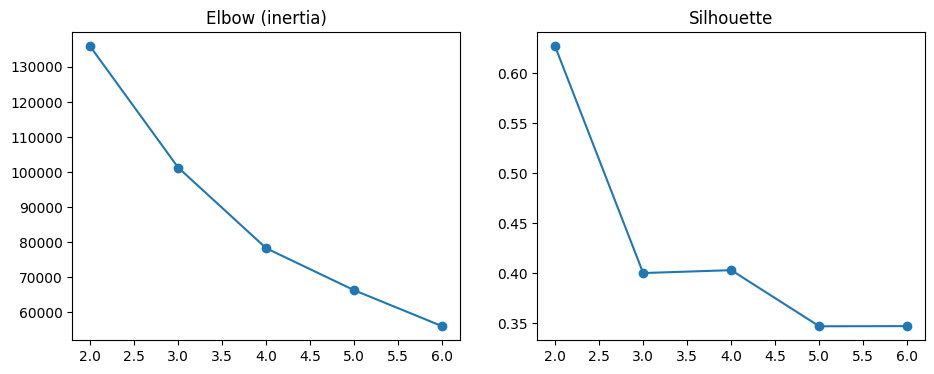

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

km_feats = ['z_log_trip_distance', 'z_duration_min', 'z_avg_speed_mph']
sample = df.sample(100_000, random_state=42)
X = sample[km_feats].values

rows = []
for k in range(2, 7):
    m = KMeans(n_clusters=k, n_init=3, random_state=42).fit(X)
    s = silhouette_score(X, m.labels_, sample_size=10_000, random_state=42)
    rows.append((k, m.inertia_, s))
res = pd.DataFrame(rows, columns=['k', 'inertia', 'silhouette'])
print(res)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(res['k'], res['inertia'], marker='o'); ax[0].set_title('Elbow (inertia)')
ax[1].plot(res['k'], res['silhouette'], marker='o'); ax[1].set_title('Silhouette')
plt.savefig(f'{OUT}/elbow_silhouette.png', dpi=150, bbox_inches='tight')
plt.show()


In [ ]:
final = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X)
df['cluster'] = final.predict(df[km_feats].values)

profile = df.groupby('cluster').agg(
    trips=('trip_distance', 'size'),
    mean_dist=('trip_distance', 'mean'),
    mean_dur=('duration_min', 'mean'),
    mean_speed=('avg_speed_mph', 'mean'),
    mean_fare=('fare_amount', 'mean'),
    airport_share=('is_airport_trip', 'mean')).round(2)
profile['pct_of_trips'] = (profile['trips'] / len(df) * 100).round(1)
profile = profile.sort_values('mean_dist')
print(profile)
profile.to_csv(f'{OUT}/cluster_profile.csv')

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

           trips  mean_dist  mean_dur  mean_speed  mean_fare  airport_share  \
cluster                                                                       
2        1647108       1.16      8.37        9.03       9.67            0.0   
0         832638       3.32     19.61       10.81      20.56           0.02   
1         348280      12.89     34.71       24.41      52.54           0.74   

         pct_of_trips  
cluster                
2                58.2  
0                29.4  
1                12.3  


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

---
# Completing the ML-Lead deliverables (Modules A, B, C + Evaluate / Interpret)

Cross-check against the proposal (Section 5, Anoushey Khushal, Mining Lead) and the Stage-4 handoff:

| Proposal item | Status before this section | Where it is now |
|---|---|---|
| **A** K-Means demand clustering, K=3 baseline | fitted + profiled, but clusters unnamed, no plots, no when/where, no validation | A4 to A7 below |
| **B** FP-Growth rules (surge question) | mined, but rules not evaluated and nothing on *driver repositioning* | B4 to B6 below |
| **C** Isolation Forest anomaly / fraud detection | **missing entirely** | Part C below |
| Stage 6 Evaluate: time-based split, leak checks | missing | A7, B6, C4 |
| Stage 7 Interpret: named clusters, rule evaluation, honest limitations | partial | A4, B4, Part D |

**Before running this section:** run the second set of cells in the same session, i.e. the data-load cell (starts with `!pip install mlxtend`), the FP-Growth basket/itemsets cell, the surge-rules cell, and the two K-Means cells (K selection, then final fit + profile). The first cell below checks this. The earlier, heavier first attempt (the cells before the data-load cell, ending with the `NameError` cell) is superseded and can be skipped.

In [ ]:
# --- Setup for the additions (needs the data-load, FP-Growth, surge-rules and K-Means cells to have run) -----------------------
need = ['df', 'PATH', 'OUT', 'MIN_SUP', 'km_feats', 'final', 'X', 'basket', 'freq', 'support', 'surge']
missing = [n for n in need if n not in globals()]
assert not missing, f"Run the data-load, FP-Growth, surge-rules and K-Means cells first. Missing: {missing}"
assert 'cluster' in df.columns, "Run the final K-Means fit + profile cell first"

import warnings; warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.metrics import adjusted_rand_score
from scipy.stats import spearmanr

# extra columns from the same file (same row order) for time-based evaluation and when/where profiling
extra = pd.read_parquet(PATH, columns=['tpep_pickup_datetime', 'pickup_hour', 'PU_zone'])
assert len(extra) == len(df), "row count mismatch between file and df"
df['pickup_dt'] = pd.to_datetime(extra['tpep_pickup_datetime']).values
df['pickup_hour'] = extra['pickup_hour'].values
df['PU_zone'] = extra['PU_zone'].values
del extra

# chronological split used by every Evaluate step below: earliest 70% of the timeline = train, latest 30% = test
cut = df['pickup_dt'].quantile(0.70)
is_train = (df['pickup_dt'] <= cut).values
print(f"timeline {df['pickup_dt'].min()} -> {df['pickup_dt'].max()} | cut at {cut}")
print(f"train rows {is_train.sum():,} | test rows {(~is_train).sum():,}")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

timeline 2024-01-01 00:00:00 -> 2024-01-31 23:59:55 | cut at 2024-01-23 11:25:38
train rows 1,979,618 | test rows 848,408


## Part A (continued): K-Means

**A4. Name the clusters (Stage 7: Interpret).** Labels are assigned by rank of mean trip distance, so they stay correct even if KMeans numbers the clusters differently on a re-run. The handoff describes three physical peaks (City Hops, Cross-Borough, Airport); the `cross_borough_share` and `airport_share` columns are the evidence for each label. Edit `names` if the evidence doesn't support one.

Why K=3 although K=2 has the highest silhouette: in the K-selection output (the elbow/silhouette cell) the silhouette is about 0.63 at K=2 and drops to about 0.40 at K=3, while K=4 scores about the same as K=3 (about 0.40). K=2 only separates "short" from "long" trips. K=3 is kept because it is the handoff baseline and it splits out the airport / long-haul group as a business-meaningful segment, and going to K=4 buys no silhouette improvement.

In [ ]:
# order clusters by mean distance and attach names (edit `names` if the evidence below disagrees)
names = ['City Hops', 'Cross-Borough', 'Airport / Long-Haul']
order = df.groupby('cluster')['trip_distance'].mean().sort_values().index.tolist()
cluster_names = dict(zip(order, names))
df['cluster_name'] = df['cluster'].map(cluster_names)
df['cross_borough'] = (df['PU_borough'] != df['DO_borough'])

named = df.groupby('cluster_name').agg(
    trips=('cluster', 'size'),
    mean_dist=('trip_distance', 'mean'),
    mean_dur=('duration_min', 'mean'),
    mean_speed=('avg_speed_mph', 'mean'),
    mean_fare=('fare_amount', 'mean'),
    airport_share=('is_airport_trip', 'mean'),
    cross_borough_share=('cross_borough', 'mean')).loc[names].round(2)
named['pct_of_trips'] = (named['trips'] / len(df) * 100).round(1)
print(named)
named.to_csv(f'{OUT}/cluster_profile_named.csv')

                       trips  mean_dist  mean_dur  mean_speed  mean_fare  \
cluster_name                                                               
City Hops            1647108       1.16      8.37        9.03       9.67   
Cross-Borough         832638       3.32     19.61       10.81      20.56   
Airport / Long-Haul   348280      12.89     34.71       24.41      52.54   

                     airport_share  cross_borough_share  pct_of_trips  
cluster_name                                                           
City Hops                      0.0                 0.00          58.2  
Cross-Borough                 0.02                 0.08          29.4  
Airport / Long-Haul           0.74                 0.81          12.3  


**A5. Visualise the segments.** Scatter in original units (clipped at the 99th percentile so a few extreme trips do not squash the plot) and cluster sizes.

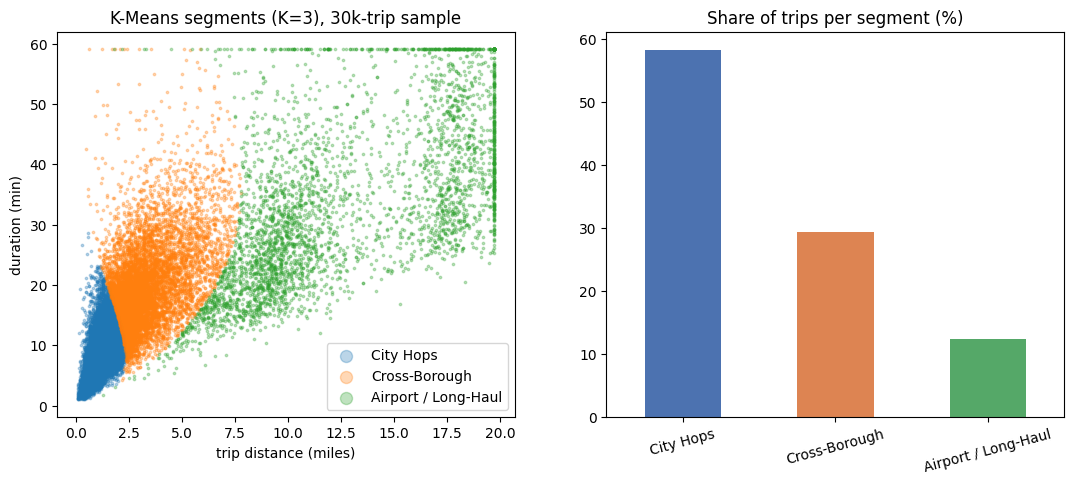

In [ ]:
viz = df.sample(30_000, random_state=1)
dmax, tmax = df['trip_distance'].quantile(0.99), df['duration_min'].quantile(0.99)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for n in names:
    s = viz[viz['cluster_name'] == n]
    ax[0].scatter(s['trip_distance'].clip(upper=dmax), s['duration_min'].clip(upper=tmax),
                  s=3, alpha=0.3, label=n)
ax[0].set_xlabel('trip distance (miles)'); ax[0].set_ylabel('duration (min)')
ax[0].set_title('K-Means segments (K=3), 30k-trip sample')
ax[0].legend(markerscale=5)
named['pct_of_trips'].plot.bar(ax=ax[1], color=['#4c72b0', '#dd8452', '#55a868'])
ax[1].set_title('Share of trips per segment (%)'); ax[1].set_xlabel('')
plt.xticks(rotation=15)
plt.savefig(f'{OUT}/cluster_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

**A6. When and where? (Research Question 1).** The proposal frames Module A as demand clustering to answer *when and where do demand spikes occur*. This profiles each segment by hour, time-of-day, pickup borough and pickup zone, then lists the biggest zone-hour spikes. `spike_idx` = trips in that zone-hour divided by that zone's average hourly volume, restricted to busy zones (top quartile by volume) so tiny zones with a handful of trips don't dominate.

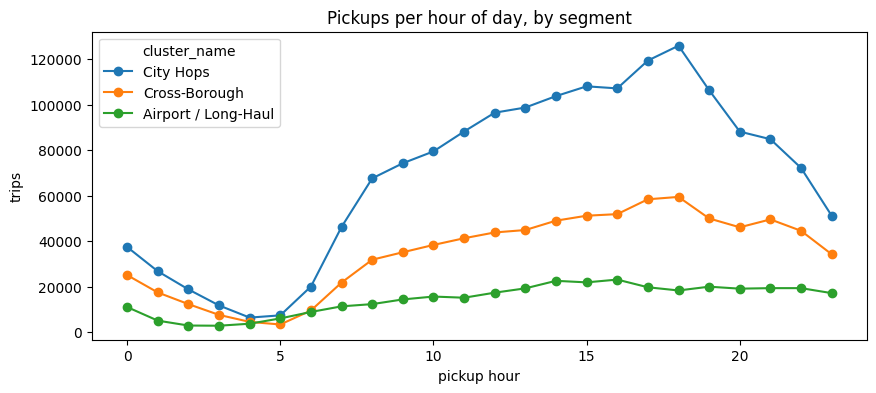

Peak pickup hour per segment:
 cluster_name
City Hops              18
Cross-Borough          18
Airport / Long-Haul    16 

Share of each segment by time_of_day:
time_of_day          Night  Morning  Afternoon  Evening
cluster_name                                           
City Hops            0.066    0.228      0.312    0.393
Cross-Borough        0.085    0.214      0.289    0.411
Airport / Long-Haul  0.092    0.224      0.300    0.383 

Share of each segment by pickup borough:
PU_borough           Bronx  Brooklyn  EWR  Manhattan  Queens  Staten Island
cluster_name                                                               
City Hops            0.000     0.003  0.0      0.993   0.004            0.0
Cross-Borough        0.002     0.012  0.0      0.961   0.025            0.0
Airport / Long-Haul  0.008     0.022  0.0      0.340   0.631            0.0 

Top 5 pickup zones, City Hops:
PU_zone
Upper East Side South    107857
Upper East Side North     97376
Midtown Center            9045

In [ ]:
hourly = df.groupby(['pickup_hour', 'cluster_name']).size().unstack(fill_value=0)[names]
ax = hourly.plot(figsize=(10, 4), marker='o', title='Pickups per hour of day, by segment')
ax.set_xlabel('pickup hour'); ax.set_ylabel('trips')
plt.savefig(f'{OUT}/hourly_by_segment.png', dpi=150, bbox_inches='tight'); plt.show()
print("Peak pickup hour per segment:\n", hourly.idxmax().to_string(), "\n")

print("Share of each segment by time_of_day:")
print(pd.crosstab(df['cluster_name'], df['time_of_day'], normalize='index').loc[names].round(3), "\n")
print("Share of each segment by pickup borough:")
print(pd.crosstab(df['cluster_name'], df['PU_borough'], normalize='index').loc[names].round(3), "\n")

for n in names:
    print(f"Top 5 pickup zones, {n}:")
    print(df.loc[df['cluster_name'] == n, 'PU_zone'].value_counts().head(5).to_string(), "\n")

zh = pd.crosstab(df['PU_zone'], df['pickup_hour'])
spike = zh.div(zh.mean(axis=1), axis=0).stack().rename('spike_idx').reset_index()
spike['trips'] = zh.stack().values
busy = zh.mean(axis=1) >= zh.mean(axis=1).quantile(0.75)
spike = spike[spike['PU_zone'].isin(busy[busy].index)]
print("Biggest zone-hour demand spikes (busy zones only):")
print(spike.sort_values('spike_idx', ascending=False).head(15).round(2).to_string(index=False))
spike.sort_values('spike_idx', ascending=False).head(200).to_csv(f'{OUT}/zone_hour_spikes.csv', index=False)

**A7. Evaluate: stability and time-based check (Stage 6).** Three checks, none of which need labels:

1. **Seed stability.** Refit K=3 with different random seeds on the same sample and compare labelings with the Adjusted Rand Index (1.0 = identical partitions).
2. **Out-of-time generalisation.** Fit scaler and K-Means on the earliest 70% of the timeline only (no look-ahead), assign the latest 30%, and compare silhouette and cluster shares between periods.
3. **Agreement with the full-data model.** ARI between the out-of-time model's labels and the final full-data model's labels (`final`) on the test period.

In [ ]:
# 1. seed stability (X = the 100k sample from the K-selection cell)
base_labels = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X)
for seed in (1, 7, 123):
    lab = KMeans(n_clusters=3, n_init=10, random_state=seed).fit_predict(X)
    print(f"seed {seed:>3} vs 42: ARI = {adjusted_rand_score(base_labels, lab):.3f}")

# 2. out-of-time: scaler + K-Means fitted on the train period only
raw = pd.DataFrame({'ld': np.log1p(df['trip_distance']),
                    'dur': df['duration_min'], 'spd': df['avg_speed_mph']})
sc = StandardScaler().fit(raw[is_train])
Xtr, Xte = sc.transform(raw[is_train]), sc.transform(raw[~is_train])

rng = np.random.RandomState(42)
tr_idx = rng.choice(len(Xtr), min(100_000, len(Xtr)), replace=False)
km_t = KMeans(n_clusters=3, n_init=10, random_state=42).fit(Xtr[tr_idx])
lab_tr, lab_te = km_t.labels_, km_t.predict(Xte)

dist_tr = df.loc[is_train, 'trip_distance'].values[tr_idx]
rank = pd.Series(dist_tr).groupby(lab_tr).mean().sort_values().index.tolist()
t_names = dict(zip(rank, names))

sub_tr = rng.choice(len(tr_idx), min(20_000, len(tr_idx)), replace=False)
sub_te = rng.choice(len(Xte), min(20_000, len(Xte)), replace=False)
print(f"\nsilhouette  train period: {silhouette_score(Xtr[tr_idx][sub_tr], lab_tr[sub_tr]):.3f}"
      f" | test period: {silhouette_score(Xte[sub_te], lab_te[sub_te]):.3f}")

shares = pd.DataFrame({
    'train_share': pd.Series(lab_tr).map(t_names).value_counts(normalize=True),
    'test_share':  pd.Series(lab_te).map(t_names).value_counts(normalize=True)}).loc[names].round(3)
print(shares)

# 3. agreement with the full-data model on the test period
print(f"\nARI (out-of-time model vs full-data model, test rows): "
      f"{adjusted_rand_score(lab_te, df.loc[~is_train, 'cluster'].values):.3f}")

seed   1 vs 42: ARI = 0.999
seed   7 vs 42: ARI = 0.996
seed 123 vs 42: ARI = 0.979

silhouette  train period: 0.407 | test period: 0.409
                     train_share  test_share
City Hops                  0.587       0.593
Cross-Borough              0.287       0.301
Airport / Long-Haul        0.125       0.106

ARI (out-of-time model vs full-data model, test rows): 0.966


## Part B (continued): FP-Growth

**B4. Evaluate the surge rules (Stage 7: rule evaluation, leak check).** The surge-rules output above shows the best rules for `is_surge_fare` have confidence of about 1.0 and lift of about 4.02. That lift is the *maximum possible*: lift = confidence / P(surge), and P(surge) is about 0.25, so no rule can exceed about 4.0. These are not discoveries. `is_surge_fare` is defined as "fare above the 75th percentile", and airport trips (especially `RatecodeID_2`, the JFK flat fare) have fares set by the tariff, not by demand. The rule just says "flat-fare airport trips are expensive". This section (a) adds leverage and conviction, (b) re-evaluates the project question *Night + Manhattan → surge* with and without airport trips, and (c) shows the rules that remain once fare-determined items are removed from the antecedent.

In [ ]:
# helpers reused in B4-B6 and Part C
def rule_stats(b, ante, cons='is_surge_fare'):
    # support / confidence / lift of ante -> cons, counted directly on boolean basket b
    a = b[list(ante)].all(axis=1).values
    c = b[cons].values.astype(bool)
    sup_a, sup_ac = a.mean(), (a & c).mean()
    conf = sup_ac / sup_a if sup_a > 0 else np.nan
    return dict(n_antecedent=int(a.sum()), support=sup_ac, confidence=conf, lift=conf / c.mean())

def mine_rules(freq_df, cons_filter, ante_filter=lambda a: True, min_conf=0.0):
    # single-consequent rules from an FP-Growth itemset table (support only needs the itemsets)
    sup = {frozenset(s): v for s, v in zip(freq_df['itemsets'], freq_df['support'])}
    rows = []
    for items, s in sup.items():
        if len(items) < 2:
            continue
        for c in items:
            if cons_filter(c):
                ante = items - {c}
                if ante in sup and ante_filter(ante):
                    conf = s / sup[ante]
                    if conf >= min_conf:
                        rows.append((tuple(sorted(ante)), c, s, conf, conf / sup[frozenset({c})]))
    return pd.DataFrame(rows, columns=['antecedent', 'consequent', 'support', 'confidence', 'lift'])

fare_structure = lambda i: i.startswith('RatecodeID_') or i == 'is_airport_trip'

# (a) all surge rules with leverage + conviction
p_surge = support[frozenset({'is_surge_fare'})]
sr = mine_rules(freq, cons_filter=lambda c: c == 'is_surge_fare')
sr['p_antecedent'] = sr['antecedent'].map(lambda a: support[frozenset(a)])
sr['leverage'] = sr['support'] - sr['p_antecedent'] * p_surge
sr['conviction'] = np.where(sr['confidence'] >= 1, np.inf, (1 - p_surge) / (1 - sr['confidence']))
print(f"P(surge) = {p_surge:.3f} -> maximum achievable lift = {1 / p_surge:.2f}")

# (c) rules whose antecedent contains no fare-structure item
clean = sr[~sr['antecedent'].map(lambda a: any(fare_structure(i) for i in a))]
print("\nTop surge rules WITHOUT airport / rate-code items in the antecedent:")
print(clean.sort_values('lift', ascending=False).head(10).round(3).to_string(index=False))

# (b) the project question, with and without airport trips
q = ['time_of_day_Night', 'PU_borough_Manhattan']
non_air = basket[~basket['is_airport_trip']]
res_q = pd.DataFrame({'all trips': rule_stats(basket, q), 'non-airport trips only': rule_stats(non_air, q)}).T
print("\nNight + Manhattan pickup -> surge fare:")
print(res_q.round(3))
sr.sort_values('lift', ascending=False).to_csv(f'{OUT}/surge_rules_with_leverage.csv', index=False)

P(surge) = 0.249 -> maximum achievable lift = 4.02

Top surge rules WITHOUT airport / rate-code items in the antecedent:
                                antecedent    consequent  support  confidence  lift  p_antecedent  leverage  conviction
  (DO_borough_Brooklyn, PU_borough_Queens) is_surge_fare    0.014       0.996 4.008         0.014     0.011     193.056
 (DO_borough_Manhattan, PU_borough_Queens) is_surge_fare    0.052       0.993 3.994         0.052     0.039     103.345
(PU_borough_Queens, time_of_day_Afternoon) is_surge_fare    0.024       0.938 3.774         0.026     0.018      12.122
  (PU_borough_Queens, time_of_day_Evening) is_surge_fare    0.036       0.935 3.763         0.038     0.026      11.595
 (DO_borough_Queens, PU_borough_Manhattan) is_surge_fare    0.025       0.931 3.744         0.027     0.018      10.835
                      (PU_borough_Queens,) is_surge_fare    0.081       0.929 3.739         0.088     0.060      10.643
  (PU_borough_Queens, time_of_day_Morni

**Reading the Night + Manhattan result.** The surge-rules output already shows lift of about 0.92 (confidence about 0.23 against a base rate of about 0.25). So the honest finding is that the pattern looks absent overall only because airport trips dominate the high fares. Among regular trips, Night + Manhattan is mildly more likely to be a high fare. Short Manhattan hops at night are cheap trips, and the expensive trips are the airport and long-haul ones. This is a legitimate negative finding and should be reported as such, not dropped.

**B5. Driver-repositioning rules (proposal Module B).** The proposal defines Module B as FP-Growth *for driver repositioning*, i.e. given where and when a trip starts, where does it end? So the consequent is a drop-off borough (`DO_borough_*`) and the antecedent uses only context a driver knows at pickup: time of day, pickup borough and airport flag. Because about 91% of trips end in Manhattan, almost every rule predicts Manhattan with lift near 1.1. The more useful view for repositioning is the second table: rules that predict a *non-Manhattan* destination, where the lift can be well above 1.

In [ ]:
dest_items = [c for c in basket.columns if c.startswith('DO_borough_')]
context_ok = lambda a: all(i.startswith(('time_of_day_', 'PU_borough_')) or i == 'is_airport_trip' for i in a)

repo = mine_rules(freq, cons_filter=lambda c: c in dest_items, ante_filter=context_ok, min_conf=0.3)
repo['antecedent'] = repo['antecedent'].map(lambda a: ' & '.join(a))

print("Top repositioning rules (any destination):")
print(repo.sort_values('lift', ascending=False).head(12).round(3).to_string(index=False))

non_manh = repo[repo['consequent'] != 'DO_borough_Manhattan']
print("\nRules predicting a NON-Manhattan drop-off (where drivers end up outside Manhattan):")
print(non_manh.sort_values('lift', ascending=False).head(12).round(3).to_string(index=False))
repo.sort_values('lift', ascending=False).to_csv(f'{OUT}/repositioning_rules.csv', index=False)

Top repositioning rules (any destination):
                                  antecedent           consequent  support  confidence   lift
      PU_borough_Manhattan & is_airport_trip    DO_borough_Queens    0.017       0.870 18.482
     is_airport_trip & time_of_day_Afternoon    DO_borough_Queens    0.011       0.355  7.547
                             is_airport_trip    DO_borough_Queens    0.033       0.340  7.210
  PU_borough_Manhattan & time_of_day_Evening DO_borough_Manhattan    0.341       0.952  1.048
  PU_borough_Manhattan & time_of_day_Morning DO_borough_Manhattan    0.192       0.948  1.044
PU_borough_Manhattan & time_of_day_Afternoon DO_borough_Manhattan    0.260       0.947  1.043
                        PU_borough_Manhattan DO_borough_Manhattan    0.852       0.944  1.040
                       time_of_day_Afternoon DO_borough_Manhattan    0.278       0.916  1.009
                         time_of_day_Evening DO_borough_Manhattan    0.364       0.914  1.007
                 

**B6. Evaluate: do the rules hold out-of-time? (Stage 6).** Rules are re-mined on a sample of the *train period only*, with the surge threshold (75th percentile of fare) computed on the train period and applied unchanged to the test period. Each top train rule is then re-counted on a sample of the *test period*. A rule is stable if its test lift stays close to its train lift and above 1. FP-Growth can take a few minutes here (the FP-Growth cell took about 3.5 minutes on 200k rows), so this uses 100k-row samples.

In [ ]:
def make_basket(d, fare_thr):
    b = pd.get_dummies(d[['time_of_day', 'RatecodeID', 'PU_borough', 'DO_borough']].astype(str), dtype=bool)
    b['is_airport_trip'] = d['is_airport_trip'].values
    b['is_surge_fare'] = (d['fare_amount'] > fare_thr).values
    return b

tr_df = df[is_train].sample(100_000, random_state=42)
te_df = df[~is_train].sample(100_000, random_state=42)
thr = tr_df['fare_amount'].quantile(0.75)            # threshold from train period only

b_tr = make_basket(tr_df, thr)
b_tr = b_tr.loc[:, b_tr.mean() >= MIN_SUP]
b_te = make_basket(te_df, thr).reindex(columns=b_tr.columns, fill_value=False).astype(bool)

t0 = time.time()
freq_tr = fpgrowth(b_tr, min_support=MIN_SUP, use_colnames=True, max_len=3)
print(f"{len(freq_tr)} train-period itemsets in {time.time() - t0:.0f}s | train surge threshold = ${thr:.2f}")

cand = pd.concat([
    mine_rules(freq_tr, cons_filter=lambda c: c == 'is_surge_fare'),
    mine_rules(freq_tr, cons_filter=lambda c: c in dest_items, ante_filter=context_ok, min_conf=0.3)])
cand = cand.sort_values('lift', ascending=False)

def eval_row(r):
    st = rule_stats(b_te, r['antecedent'], r['consequent'])
    return pd.Series({'test_support': st['support'], 'test_confidence': st['confidence'], 'test_lift': st['lift']})

top = pd.concat([cand[cand['consequent'] == 'is_surge_fare'].head(8),
                 cand[(cand['consequent'] != 'is_surge_fare') & (cand['consequent'] != 'DO_borough_Manhattan')].head(8)])
stab = pd.concat([top.reset_index(drop=True), top.apply(eval_row, axis=1).reset_index(drop=True)], axis=1)
stab['antecedent'] = stab['antecedent'].map(lambda a: ' & '.join(a))
stab = stab.rename(columns={'support': 'train_support', 'confidence': 'train_confidence', 'lift': 'train_lift'})
print(stab.round(3).to_string(index=False))
print(f"\nShare of these rules with test lift > 1: {(stab['test_lift'] > 1).mean():.0%}")
stab.to_csv(f'{OUT}/rule_stability_out_of_time.csv', index=False)

163 train-period itemsets in 38s | train surge threshold = $19.80
                             antecedent        consequent  train_support  train_confidence  train_lift  test_support  test_confidence  test_lift
         RatecodeID_2 & is_airport_trip     is_surge_fare          0.036             1.000       4.008         0.025            1.000      4.122
     RatecodeID_2 & time_of_day_Evening     is_surge_fare          0.014             1.000       4.008         0.010            1.000      4.122
   RatecodeID_2 & time_of_day_Afternoon     is_surge_fare          0.012             1.000       4.008         0.010            1.000      4.122
       PU_borough_Queens & RatecodeID_2     is_surge_fare          0.029             1.000       4.008         0.019            1.000      4.122
                           RatecodeID_2     is_surge_fare          0.036             1.000       4.008         0.025            1.000      4.122
  DO_borough_Brooklyn & is_airport_trip     is_surge_fare       

## **Part C: Isolation Forest, anomaly and fraud detection (Module C)**

Per the handoff: **raw, unscaled** `trip_distance`, `fare_amount`, `duration_min`, because the forest has to see the true multivariate relationships (the handoff's example: a 1-mile trip that costs $80). Isolation Forest is unsupervised, so there are no ground-truth fraud labels. The evaluation therefore uses (1) inspection of what gets flagged, (2) planted anomalies with known answers, and (3) stability across seeds and across time.

**C1. Fit and score.** `contamination=0.01` means "flag the 1% most isolated trips" and is an assumption, not a measurement; the threshold can be moved later with `iso.offset_`. The forest is fitted on a 200k sample, then scores every trip.

In [ ]:
iso_feats = ['trip_distance', 'fare_amount', 'duration_min']      # raw units, per handoff
CONTAMINATION = 0.01
rng = np.random.RandomState(42)

fit_idx = rng.choice(len(df), min(200_000, len(df)), replace=False)
iso = IsolationForest(n_estimators=200, max_samples=1024, contamination=CONTAMINATION,
                      random_state=42, n_jobs=-1)
iso.fit(df[iso_feats].values[fit_idx])

vals = df[iso_feats].values
score = np.concatenate([-iso.score_samples(vals[i:i + 500_000]) for i in range(0, len(vals), 500_000)])
df['anomaly_score'] = score                               # higher = more isolated = more anomalous
df['is_anomaly'] = score > -iso.offset_
print(f"flagged {df['is_anomaly'].sum():,} of {len(df):,} trips ({df['is_anomaly'].mean():.2%})")

flagged 28,754 of 2,828,026 trips (1.02%)


**C2. What did it flag?** `fare_per_mile` and `fare_per_min` are diagnostics only, they are not model inputs. Each flagged trip is assigned a plain-language reason by rule (thresholds visible in the code). Airport / flat-rate trips and long trips whose fare per mile is normal are labelled separately as likely legitimate, because they are rare (so the forest isolates them) but not suspicious.

In [ ]:
df['fare_per_mile'] = df['fare_amount'] / df['trip_distance'].clip(lower=0.1)
df['fare_per_min'] = df['fare_amount'] / df['duration_min'].clip(lower=1)
diag = ['trip_distance', 'duration_min', 'avg_speed_mph', 'fare_amount', 'fare_per_mile', 'fare_per_min']
print("Median profile, flagged vs normal:")
print(df.groupby('is_anomaly')[diag].median().round(2).rename(index={False: 'normal', True: 'flagged'}), "\n")

fl = df[df['is_anomaly']].copy()
conds = [
    (fl['fare_per_mile'] > 15) & (fl['trip_distance'] < 3),
    (fl['duration_min'] > 120) | ((fl['duration_min'] > 60) & (fl['trip_distance'] < 2)),
    fl['avg_speed_mph'] > 60,
    fl['trip_distance'] > 30,
    fl['is_airport_trip'] | fl['RatecodeID'].isin([2, 3]),
    (fl['trip_distance'] > 15) & (fl['fare_per_mile'] < 8)]
labels = ['High fare for a short trip', 'Very long duration / idle meter', 'Implausible speed',
          'Extreme distance', 'Airport / flat-rate (likely legitimate)',
          'Long trip with consistent fare (likely legitimate)']
fl['reason'] = np.select(conds, labels, default='Other multivariate outlier')
print("Why trips were flagged:")
print(pd.concat([fl['reason'].value_counts().rename('trips'),
                 fl['reason'].value_counts(normalize=True).round(3).rename('share')], axis=1), "\n")

print("Top 15 most anomalous trips:")
print(fl.sort_values('anomaly_score', ascending=False)
        [['trip_distance', 'duration_min', 'fare_amount', 'RatecodeID', 'PU_borough', 'DO_borough', 'reason']]
        .head(15).to_string())

cols_out = iso_feats + ['avg_speed_mph', 'fare_per_mile', 'RatecodeID', 'PU_borough', 'DO_borough', 'anomaly_score', 'reason']
fl.sort_values('anomaly_score', ascending=False)[cols_out].to_csv(f'{OUT}/iso_flagged_trips.csv', index=False)

Median profile, flagged vs normal:
            trip_distance  duration_min  avg_speed_mph  fare_amount  \
is_anomaly                                                            
normal               1.70         11.62           9.63         12.8   
flagged             18.06         59.95          17.88         70.0   

            fare_per_mile  fare_per_min  
is_anomaly                               
normal               7.20          1.16  
flagged              4.03          1.35   

Why trips were flagged:
                                                    trips  share
reason                                                          
Airport / flat-rate (likely legitimate)             16990  0.591
Other multivariate outlier                           5682  0.198
Long trip with consistent fare (likely legitimate)   2844  0.099
High fare for a short trip                           1791  0.062
Very long duration / idle meter                       739  0.026
Extreme distance               

**C3. Evaluate with planted anomalies (known answers).** Three synthetic fraud patterns are built from real trips and scored with the already-fitted forest: (1) the handoff example, 1-mile trips billed $70 to $90; (2) *meter gouging*, real trips with the fare tripled; (3) *idle / stuck meter*, real trips with duration multiplied by 6. **Detection rate** = share flagged. The untouched control shows the false-alarm rate. Pattern 2 is expected to be weaker for short cheap trips (a $9 fare tripled is only $27, which is a normal fare for a longer trip), and the numbers will show that.

In [ ]:
n = 20_000
base = df[iso_feats].iloc[rng.choice(len(df), n, replace=False)].copy()

scen = {
    'control (untouched real trips)': base,
    '1-mile trip billed $70-90': pd.DataFrame({'trip_distance': 1.0,
                                               'fare_amount': rng.uniform(70, 90, n),
                                               'duration_min': rng.uniform(5, 12, n)}),
    'meter gouging (fare x3)': base.assign(fare_amount=base['fare_amount'] * 3),
    'idle meter (duration x6)': base.assign(duration_min=base['duration_min'] * 6)}

out = {k: float((iso.score_samples(v[iso_feats].values) < iso.offset_).mean()) for k, v in scen.items()}
print(pd.Series(out, name='share flagged').round(3).to_string())

control (untouched real trips)    0.010
1-mile trip billed $70-90         1.000
meter gouging (fare x3)           0.207
idle meter (duration x6)          0.584


**C3b. Optional experiment: add ratio features.** If *1-mile trip billed $70-90* has a low detection rate above, that is a real limitation, not a bug: flat-rate airport fares of $70 or more are common, so an $80 fare is not isolated on raw distance, fare and duration alone. Adding `fare_per_mile` and `fare_per_min` (derived, unscaled) may or may not help, since short trips naturally have a very high fare per mile, so the table below is the test. The handoff-specified 3-feature model stays the primary Module C result; this cell only shows whether extra features are worth proposing to the team. Same planted anomalies, same contamination.

In [ ]:
def with_ratios(d):
    d = d[iso_feats].copy()
    d['fare_per_mile'] = d['fare_amount'] / d['trip_distance'].clip(lower=0.1)
    d['fare_per_min'] = d['fare_amount'] / d['duration_min'].clip(lower=1)
    return d

feats_r = iso_feats + ['fare_per_mile', 'fare_per_min']
iso_r = IsolationForest(n_estimators=200, max_samples=1024, contamination=CONTAMINATION,
                        random_state=42, n_jobs=-1)
iso_r.fit(with_ratios(df.iloc[fit_idx])[feats_r].values)

cmp = pd.DataFrame({
    '3 raw features (handoff)': out,
    '+ fare_per_mile, fare_per_min': {k: float((iso_r.score_samples(with_ratios(v)[feats_r].values) < iso_r.offset_).mean())
                                      for k, v in scen.items()}})
print(cmp.round(3).to_string())

                                3 raw features (handoff)  + fare_per_mile, fare_per_min
control (untouched real trips)                     0.010                          0.009
1-mile trip billed $70-90                          1.000                          1.000
meter gouging (fare x3)                            0.207                          0.997
idle meter (duration x6)                           0.584                          0.392


**C4. Evaluate: stability across seeds and across time.** (a) Two forests with different seeds should rank trips almost identically (Spearman correlation of scores, plus overlap of the flagged sets). (b) A forest fitted on the earliest 70% of the timeline, with its threshold frozen, is applied to the latest 30%: the flag rate should stay close to the 1% contamination if the notion of "normal" is stable over time.

In [ ]:
# (a) seed stability on a 100k evaluation sample
ev = rng.choice(len(df), min(100_000, len(df)), replace=False)
fit2 = rng.choice(len(df), min(200_000, len(df)), replace=False)
isoA = IsolationForest(n_estimators=200, max_samples=1024, contamination=CONTAMINATION, random_state=1, n_jobs=-1).fit(vals[fit2])
isoB = IsolationForest(n_estimators=200, max_samples=1024, contamination=CONTAMINATION, random_state=2, n_jobs=-1).fit(vals[fit2])
sA, sB = -isoA.score_samples(vals[ev]), -isoB.score_samples(vals[ev])
fA, fB = sA > -isoA.offset_, sB > -isoB.offset_
print(f"seed stability: Spearman = {spearmanr(sA, sB)[0]:.3f} | flagged-set Jaccard = {(fA & fB).sum() / (fA | fB).sum():.3f}")

# (b) out-of-time: fit on train period, freeze threshold, apply to test period
tr_rows = np.where(is_train)[0]
iso_t = IsolationForest(n_estimators=200, max_samples=1024, contamination=CONTAMINATION, random_state=42, n_jobs=-1)
iso_t.fit(vals[rng.choice(tr_rows, min(200_000, len(tr_rows)), replace=False)])
flag_all = iso_t.score_samples(vals) < iso_t.offset_
print(f"out-of-time flag rate (target {CONTAMINATION:.1%}): "
      f"train period = {flag_all[is_train].mean():.2%} | test period = {flag_all[~is_train].mean():.2%}")

seed stability: Spearman = 0.972 | flagged-set Jaccard = 0.891
out-of-time flag rate (target 1.0%): train period = 1.00% | test period = 0.92%


## Part D: Honest limitations (Stage 7)

**K-Means (Module A)**
- `z_avg_speed_mph` is derived from distance and duration, so the three features are partly redundant and speed carries distance and time information a second time.
- K-Means is distance-based and pulled by outliers (duration reaches about 14 standard deviations in the z-scored data), and it assumes roughly spherical clusters. Silhouette at K=3 is only about 0.40, so segments overlap at their edges.
- The segments are behavioural (trip shape), not geographic. A6 adds the *where* and *when* by profiling segments afterwards; it is not a spatial clustering of zones.
- Evaluation in A7 is stability-based; unsupervised clustering has no ground truth.

**FP-Growth (Module B)**
- The strongest surge rules are structural (airport and flat-rate fares), as B4 shows. Reporting them as insights would be misleading.
- `is_surge_fare` is a percentile of the sample's own fares, so it is relative to this dataset and period, not an observed surge multiplier. The data has no real surge or demand signal.
- Borough items are very imbalanced (about 91% Manhattan), so lift on Manhattan destinations is capped near 1.1. Zone-level items would be more informative for repositioning but need much lower support thresholds, which is slow on a 200k-row basket.
- Rules are associations, not causes.

**Isolation Forest (Module C)**
- There are no fraud labels, so detection quality is shown only through planted anomalies (which are our assumptions about what fraud looks like) and stability. "Flagged" means "unusual", not "fraudulent".
- `contamination` fixes the flag rate by construction; it is a business choice. In production, thresholds should be tuned to review capacity.
- Legitimate flat-rate airport and long-haul trips can look anomalous; C2 quantifies how much of the flagged set they make up.
- Only three features are used, as instructed in the handoff. Location, time of day and tolls could separate more patterns.

**General**
- Everything here is limited to the period in the parquet. Time-based checks only show stability *within* that window.
- The "surge rules without airport items" table is led by PU_borough_Queens. In this data, Queens pickups are mostly JFK and LaGuardia, so Queens is a stand-in for airport trips. Those rules are still the airport effect.
- About 59% of Isolation Forest flags are airport or flat-rate trips that are likely legitimate. Only about 11% are plausibly suspicious: short trips with high fares, idle meters, extreme distance, or implausible speed. Report that figure rather than "28,754 anomalies".

In [ ]:
import joblib, sklearn
SAVE = '/content/drive/MyDrive/DRIFT_outputs/saved_models'
os.makedirs(SAVE, exist_ok=True)

# keep the scaler this time (same column order as km_feats)
raw_feats = ['log_trip_distance', 'duration_min', 'avg_speed_mph']
scaler = StandardScaler().fit(df[raw_feats])

joblib.dump({
    'scaler': scaler,
    'kmeans': final,
    'raw_features': raw_feats,          # input order for the scaler
    'cluster_names': cluster_names,     # {cluster_id: 'City Hops', ...}
    'sklearn_version': sklearn.__version__,
}, f'{SAVE}/kmeans_bundle.pkl')

joblib.dump({
    'model': iso,
    'features': iso_feats,              # raw trip_distance, fare_amount, duration_min
    'threshold': -iso.offset_,          # anomaly_score > threshold = flagged
    'sklearn_version': sklearn.__version__,
}, f'{SAVE}/isoforest_bundle.pkl')

# small rule tables for the app (JSON, since CSVs are forbidden in Git)
repo.head(200).to_json(f'{SAVE}/repositioning_rules.json', orient='records')
sr.sort_values('lift', ascending=False).head(200).to_json(f'{SAVE}/surge_rules.json', orient='records')

print(sklearn.__version__)

1.6.1
